# Análise Exploratória de Dados: UEFA Nations League 2026/27

**ELE0604 - Redes Neurais Artificiais** · UFRN · Trabalho 1

Leonardo Barbosa e Matheus Salviano

## Objetivo

No trabalho seguinte vamos treinar uma rede densa (MLP) com backpropagation. O alvo
escolhido é a classificação da posição tática do jogador (`GOALKEEPER`, `DEFENDER`,
`MIDFIELDER`, `FORWARD`) a partir das métricas de desempenho em campo. Queremos verificar
se a função tática de um jogador pode ser recuperada do seu perfil estatístico.

Esta análise prepara o par $(x, y)$ para esse treinamento. É preciso decidir quais colunas
podem compor $x$, confirmar que nenhuma delas vaza $y$, corrigir o que distorce a comparação
entre jogadores e colocar tudo na escala que as funções de ativação exigem.

## Como executar

Os sete arquivos CSV do dataset precisam estar na pasta `dados/` ou no mesmo diretório
deste notebook. Rode as células de cima para baixo: as figuras são gravadas em `figuras/`
e o conjunto preparado em `dados_preparados.npz`.

Dependências: `pandas`, `numpy`, `matplotlib`, `scipy` e `scikit-learn`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Os CSV podem estar na pasta dados/ (layout do repositorio) ou ao lado do notebook
DADOS = Path("dados") if (Path("dados") / "players_summary.csv").exists() else Path(".")
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)

# ---- Padrão visual ---------------------------------------------------------
SUP, TINTA, SEC, MUDO = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRADE, EIXO = "#e1e0d9", "#c3c2b7"
# Paleta categórica validada (ordem fixa; a cor acompanha a classe, nunca o ranking)
CORES = {"GOALKEEPER": "#2a78d6", "DEFENDER": "#eb6834",
         "MIDFIELDER": "#1baf7a", "FORWARD": "#eda100"}
ORDEM = ["GOALKEEPER", "DEFENDER", "MIDFIELDER", "FORWARD"]
ROTULO = {"GOALKEEPER": "Goleiro", "DEFENDER": "Zagueiro",
          "MIDFIELDER": "Meia", "FORWARD": "Atacante"}
# Divergente azul <-> vermelho com ponto neutro cinza, para correlação
CMAP = LinearSegmentedColormap.from_list("div", ["#184f95", "#86b6ef", "#f0efec",
                                                 "#ef8a89", "#a62726"])

mpl.rcParams.update({
    "figure.facecolor": SUP, "axes.facecolor": SUP, "savefig.facecolor": SUP,
    "figure.dpi": 130, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 9.5, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 9.5, "axes.labelcolor": SEC,
    "text.color": TINTA, "xtick.color": MUDO, "ytick.color": MUDO,
    "axes.edgecolor": EIXO, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRADE, "grid.linewidth": 0.7, "axes.grid": False,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 8,
})

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. Descrição do conjunto de dados

O dataset é o *UEFA Nations League 2026*, publicado no Kaggle pelo autor `subhashb21022`
sob licença CC BY-SA 4.0 (versão 2, cerca de 2,3 MB). Os dados foram extraídos dos endpoints
JSON oficiais da UEFA (`compstats.uefa.com` e `match.uefa.com`) e cobrem a fase de liga do
torneio 2026/27 até a 4ª rodada: 54 seleções distribuídas em quatro divisões (Ligas A, B, C
e D), 104 partidas disputadas e 1.468 jogadores.

Os arquivos vêm em CSV com codificação `utf-8-sig` (com BOM), o que preserva a acentuação
dos nomes próprios.

In [2]:
ARQUIVOS = ["players_summary.csv", "players_latest.csv", "teams_summary.csv",
            "teams_latest.csv", "finished_matches.csv", "matches.csv",
            "group_standings.csv"]
tab = []
for a in ARQUIVOS:
    d = pd.read_csv(DADOS / a, encoding="utf-8-sig")
    tab.append({"arquivo": a, "linhas": len(d), "colunas": d.shape[1],
                "KB": round((DADOS / a).stat().st_size / 1024, 1)})
inventario = pd.DataFrame(tab)
inventario

,arquivo,linhas,colunas,KB
0,players_summary.csv,1468,44,288.30
1,players_latest.csv,11752,47,"1,773.70"
2,teams_summary.csv,54,45,11.80
3,teams_latest.csv,432,48,53.70
4,finished_matches.csv,104,34,25.10
5,matches.csv,156,34,37.70
6,group_standings.csv,54,14,3.10


### 1.1 Qual tabela sustenta uma rede neural?

A escolha da tabela de trabalho é uma restrição estatística, não uma preferência. Uma MLP
densa com uma camada oculta de 32 unidades sobre 30 entradas já tem cerca de mil parâmetros.
Treinar isso com algumas dezenas de amostras produz memorização, não aprendizado.

| Tabela | Amostras | Veredito |
|---|---|---|
| `players_summary` | 1.468 | Única com volume suficiente |
| `players_latest` | 11.752 | Formato longo: 8 categorias por jogador, não são amostras independentes |
| `finished_matches` | 104 | Insuficiente para 3 classes |
| `teams_summary`, `group_standings` | 54 | Insuficiente |
| `teams_latest` | 432 | Formato longo dos mesmos 54 times |

As duas tabelas `*_latest` são a versão longa das tabelas `*_summary`: mesmas métricas,
quebradas nas oito categorias oficiais da UEFA, com três colunas extras de proveniência.
A verificação abaixo confirma que não há informação nova nelas.

In [3]:
ps = pd.read_csv(DADOS / "players_summary.csv", encoding="utf-8-sig")
pl = pd.read_csv(DADOS / "players_latest.csv", encoding="utf-8-sig")

print(f"players_summary : {ps.shape[0]} linhas x {ps.shape[1]} colunas")
print(f"players_latest  : {pl.shape[0]} linhas x {pl.shape[1]} colunas")
print(f"\ncategorias em players_latest: {sorted(pl.source_stat_category.unique())}")
print(f"linhas por jogador em players_latest: "
      f"{pl.groupby('player_id').size().unique()}  (8 = uma por categoria)")
print(f"colunas exclusivas de players_latest: {sorted(set(pl.columns) - set(ps.columns))}")
print(f"\n=> players_latest nao acrescenta metrica alguma. Descartada.")

players_summary : 1468 linhas x 44 colunas
players_latest  : 11752 linhas x 47 colunas

categorias em players_latest: ['attacking', 'attempts', 'defending', 'disciplinary', 'distribution', 'goalkeeping', 'goals', 'key_stats']
linhas por jogador em players_latest: [8]  (8 = uma por categoria)
colunas exclusivas de players_latest: ['as_of_date', 'scraped_at', 'source_stat_category']

=> players_latest nao acrescenta metrica alguma. Descartada.


### 1.2 Vazamento nas tabelas de partida

Mesmo que o volume permitisse, `finished_matches.csv` traria um segundo problema. As colunas
`home_score`, `away_score`, `total_goals`, `goal_difference`, `winner_team_name`,
`winner_team_id`, `home_points` e `away_points` são funções determinísticas do rótulo
`result`. Já `group_standings.csv` e `teams_summary.csv` são agregados calculados depois de
todas as partidas, então usá-los para prever partidas já disputadas é vazamento temporal.
Fica registrado como achado da análise, não como caminho a seguir.

In [4]:
fm = pd.read_csv(DADOS / "finished_matches.csv", encoding="utf-8-sig")
chave = (np.sign(fm.home_score - fm.away_score)
         .map({1: "HOME_WIN", -1: "AWAY_WIN", 0: "DRAW"}))
print(f"'result' reconstruido a partir do placar: "
      f"{(chave == fm.result).sum()}/{len(fm)} linhas  -> vazamento perfeito\n")
print("distribuicao de 'result':")
print(fm.result.value_counts().to_frame("partidas")
        .assign(pct=lambda d: (d.partidas / len(fm) * 100).round(2)))

'result' reconstruido a partir do placar: 104/104 linhas  -> vazamento perfeito

distribuicao de 'result':
          partidas   pct
result                  
HOME_WIN        39 37.50
AWAY_WIN        37 35.58
DRAW            28 26.92


## 2. Estrutura de `players_summary.csv`

São 44 colunas: seis de identificação e trinta e oito métricas, organizadas nos oito
domínios oficiais da UEFA (tempo em campo, gols, finalizações, distribuição, ataque, defesa,
goleiro e disciplina).

In [5]:
ident = ["player_id", "player_name", "country_code", "position", "team_id", "team_name"]
BLOCOS = {
    "Tempo":        ["minutes_played_official", "matches_appearance",
                     "top_speed", "distance_covered"],
    "Gols":         ["goals", "goals_scored_with_right", "goals_scored_with_left",
                     "goals_scored_head", "goals_scored_other",
                     "goals_scored_inside_penalty_area",
                     "goals_scored_outside_penalty_area", "penalty_scored"],
    "Finalizacao":  ["attempts", "attempts_on_target", "attempts_off_target",
                     "attempts_blocked"],
    "Distribuicao": ["passes_accuracy", "passes_attempted", "passes_completed",
                     "cross_accuracy", "cross_attempted", "cross_completed", "free_kick"],
    "Ataque":       ["assists", "corners", "offsides"],
    "Defesa":       ["recovered_ball", "tackles", "clearance_attempted"],
    "Goleiro":      ["saves", "goals_conceded", "saves_on_penalty", "clean_sheet", "punches"],
    "Disciplina":   ["fouls_committed", "fouls_suffered", "yellow_cards", "red_cards"],
}
DE_BLOCO = {c: b for b, cs in BLOCOS.items() for c in cs}

print(f"identificacao ({len(ident)}): {ident}")
for b, cs in BLOCOS.items():
    print(f"{b:13s} ({len(cs):2d}): {', '.join(cs)}")
print(f"\ntotal mapeado: {len(ident) + sum(len(c) for c in BLOCOS.values())} de {ps.shape[1]}")
print(f"tipos: {ps.dtypes.astype(str).value_counts().to_dict()}")

identificacao (6): ['player_id', 'player_name', 'country_code', 'position', 'team_id', 'team_name']
Tempo         ( 4): minutes_played_official, matches_appearance, top_speed, distance_covered
Gols          ( 8): goals, goals_scored_with_right, goals_scored_with_left, goals_scored_head, goals_scored_other, goals_scored_inside_penalty_area, goals_scored_outside_penalty_area, penalty_scored
Finalizacao   ( 4): attempts, attempts_on_target, attempts_off_target, attempts_blocked
Distribuicao  ( 7): passes_accuracy, passes_attempted, passes_completed, cross_accuracy, cross_attempted, cross_completed, free_kick
Ataque        ( 3): assists, corners, offsides
Defesa        ( 3): recovered_ball, tackles, clearance_attempted
Goleiro       ( 5): saves, goals_conceded, saves_on_penalty, clean_sheet, punches
Disciplina    ( 4): fouls_committed, fouls_suffered, yellow_cards, red_cards

total mapeado: 44 de 44
tipos: {'float64': 40, 'str': 4}


## 3. Qualidade dos dados

### 3.1 O bloco de 235 ausências simultâneas

Quase todas as métricas têm exatamente 235 valores nulos, nas mesmas linhas. Não é ruído de
coleta: são jogadores convocados que não entraram em campo. Eles constam da lista da UEFA,
mas não produziram nenhuma estatística.

In [6]:
nulos = ps.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
print("colunas com nulos:")
print(nulos.to_frame("nulos").assign(pct=lambda d: (d.nulos / len(ps) * 100).round(1)))

sem_jogo = ps.minutes_played_official.isna()
print(f"\nlinhas sem minutos: {sem_jogo.sum()} ({sem_jogo.mean()*100:.1f}%)")
print(f"as mesmas 235 linhas em 'goals'? {bool((sem_jogo == ps.goals.isna()).all())}")
print("\nposicao dos nao-utilizados:")
print(ps.loc[sem_jogo, "position"].value_counts().to_frame("jogadores")
        .assign(pct_da_posicao=lambda d: (d.jogadores /
                ps.position.value_counts() * 100).round(1)))

colunas com nulos:
                                   nulos   pct
top_speed                            305 20.80
distance_covered                     305 20.80
minutes_played_official              235 16.00
goals                                235 16.00
matches_appearance                   235 16.00
assists                              235 16.00
goals_scored_with_right              235 16.00
goals_scored_with_left               235 16.00
goals_scored_head                    235 16.00
goals_scored_other                   235 16.00
goals_scored_inside_penalty_area     235 16.00
goals_scored_outside_penalty_area    235 16.00
penalty_scored                       235 16.00
attempts                             235 16.00
attempts_on_target                   235 16.00
attempts_off_target                  235 16.00
attempts_blocked                     235 16.00
passes_accuracy                      235 16.00
passes_attempted                     235 16.00
passes_completed                     235 

O recorte por posição é revelador: 54% de todos os goleiros do torneio nunca jogaram
(101 de 187), contra 7% dos atacantes. Isso vem direto da regra do futebol, já que cada
seleção leva três goleiros e usa um. A assimetria diz algo real sobre o torneio, mas não
serve como entrada, porque essas linhas não têm métrica nenhuma para alimentar a rede.

### 3.2 Três colunas preenchidas de forma inconsistente

`cross_accuracy`, `yellow_cards` e `red_cards` fogem do padrão de 235 nulos e têm 0 ou 2.
Nelas o autor do dataset gravou zero onde deveria haver ausência, o que torna
indistinguíveis "não cruzou" e "não jogou".

In [7]:
print("nas 235 linhas de jogadores que nao entraram em campo:")
for c in ["cross_accuracy", "yellow_cards", "red_cards", "passes_accuracy"]:
    s = ps.loc[sem_jogo, c]
    print(f"  {c:18s} nulos={s.isna().sum():4d}  zeros={(s == 0).sum():4d}  "
          f"soma={np.nansum(s):.0f}")
print("\n=> zero imputado silenciosamente. Se essas linhas fossem mantidas, as tres")
print("   colunas carregariam um sinal falso ('nunca errou um cruzamento').")

nas 235 linhas de jogadores que nao entraram em campo:
  cross_accuracy     nulos=   0  zeros= 235  soma=0
  yellow_cards       nulos=   2  zeros= 233  soma=0
  red_cards          nulos=   2  zeros= 233  soma=0
  passes_accuracy    nulos= 235  zeros=   0  soma=0

=> zero imputado silenciosamente. Se essas linhas fossem mantidas, as tres
   colunas carregariam um sinal falso ('nunca errou um cruzamento').


### 3.3 Um jogador duplicado

São 1.468 `player_id` distintos, mas apenas 1.467 nomes.

In [8]:
dup = ps[ps.player_name.duplicated(keep=False)]
dup[["player_id", "player_name", "team_name", "position",
     "minutes_played_official", "matches_appearance"]]

,player_id,player_name,team_name,position,minutes_played_official,matches_appearance
176,"250,172,707.00",Aral Şimşir,Türki̇ye,MIDFIELDER,70.00,1.00
1348,"250,124,570.00",Aral Şimşir,Türki̇ye,FORWARD,NaN,NaN


O mesmo atleta aparece duas vezes, com `player_id` diferentes e posições conflitantes. A
UEFA o registrou em duas convocações. A linha `FORWARD` está entre as 235 sem minutos, então
o filtro da seção 4 resolve o conflito sozinho. Ainda assim fica o alerta de que `player_id`
não é chave confiável de pessoa.

### 3.4 Uma coluna sem variância

`punches` (socos do goleiro) é zero para todos os 1.233 jogadores que entraram em campo. Com
variância nula ela não distingue nada e ainda quebraria a padronização por divisão por zero.

In [9]:
jogou = ps[~sem_jogo]
const = [c for c in ps.select_dtypes(include=[np.number]).columns
         if jogou[c].nunique(dropna=True) <= 1]
for c in const:
    print(f"  {c}: valor unico = {jogou[c].dropna().unique()}  (desvio={jogou[c].std():.4f})")

  punches: valor unico = [0.]  (desvio=0.0000)


### 3.5 Identidades estruturais e as linhas que as quebram

Três grupos de colunas são somas exatas de outros. Não é correlação alta, é redundância
perfeita, que inflaria a dimensão de entrada sem acrescentar informação. Testar as
identidades tem um efeito colateral útil: as poucas linhas que não fecham são erros da fonte.

In [10]:
def identidade(nome, total, partes):
    s = jogou[[total] + partes].dropna()
    dif = (s[total] - s[partes].sum(axis=1)).abs() > 1e-9
    print(f"{nome}\n    fecham em {len(s) - dif.sum()}/{len(s)} linhas"
          f"{'' if dif.sum() == 0 else f'  -> {dif.sum()} inconsistencia(s)'}")
    return jogou.loc[s.index[dif]]

q1 = identidade("goals = pe direito + pe esquerdo + cabeca + outro", "goals",
                ["goals_scored_with_right", "goals_scored_with_left",
                 "goals_scored_head", "goals_scored_other"])
q2 = identidade("goals = dentro da area + fora da area", "goals",
                ["goals_scored_inside_penalty_area", "goals_scored_outside_penalty_area"])
q3 = identidade("attempts = no gol + para fora + bloqueadas", "attempts",
                ["attempts_on_target", "attempts_off_target", "attempts_blocked"])

print("\nlinhas inconsistentes:")
pd.concat([q1, q2, q3]).drop_duplicates("player_id")[
    ["player_name", "team_name", "position", "goals", "goals_scored_with_right",
     "goals_scored_head", "attempts", "attempts_on_target", "attempts_blocked"]]

goals = pe direito + pe esquerdo + cabeca + outro
    fecham em 1232/1233 linhas  -> 1 inconsistencia(s)
goals = dentro da area + fora da area
    fecham em 1231/1233 linhas  -> 2 inconsistencia(s)
attempts = no gol + para fora + bloqueadas
    fecham em 1231/1233 linhas  -> 2 inconsistencia(s)

linhas inconsistentes:


,player_name,team_name,position,goals,goals_scored_with_right,goals_scored_head,attempts,attempts_on_target,attempts_blocked
148,Ryan Christie,Scotland,MIDFIELDER,1.00,0.00,0.00,2.00,2.00,0.00
97,Haris Tabaković,Bosnia and Herzegovina,FORWARD,1.00,0.00,0.00,2.00,1.00,0.00
162,Marco Pašalić,Croatia,FORWARD,1.00,0.00,0.00,2.00,1.00,1.00
708,Ianis Hagi,Romania,MIDFIELDER,0.00,0.00,0.00,6.00,0.00,3.00
944,Eric Veiga,Luxembourg,MIDFIELDER,0.00,0.00,0.00,1.00,0.00,0.00


### 3.6 `passes_accuracy` não é exatamente a razão recalculada

A documentação define a precisão de passe como percentual de passes completados. Recalcular
a razão a partir de `passes_completed / passes_attempted` mostra que a coluna original não é
reprodutível.

In [11]:
s = jogou[jogou.passes_attempted > 0].copy()
s["recalculado"] = 100 * s.passes_completed / s.passes_attempted
s["erro"] = (s.passes_accuracy - s.recalculado).abs()
print(f"erro absoluto: mediana={s.erro.median():.2f} p.p. | "
      f"p95={s.erro.quantile(.95):.2f} | max={s.erro.max():.2f}")
print(f"dentro de +-1 p.p. (arredondamento): {(s.erro <= 1).mean()*100:.1f}%\n")
s.nlargest(5, "erro")[["player_name", "position", "passes_attempted",
                       "passes_completed", "passes_accuracy", "recalculado", "erro"]]

erro absoluto: mediana=0.63 p.p. | p95=13.57 | max=50.00
dentro de +-1 p.p. (arredondamento): 59.4%



,player_name,position,passes_attempted,passes_completed,passes_accuracy,recalculado,erro
986,Dávid Ďuriš,FORWARD,15.00,15.00,50.00,100.00,50.00
1070,Daniel Dumbrăvanu,FORWARD,12.00,12.00,50.00,100.00,50.00
1130,Leandro Trossard,MIDFIELDER,6.00,6.00,50.00,100.00,50.00
1156,Oskar Pietuszewski,FORWARD,4.00,4.00,50.00,100.00,50.00
1157,Nuno Tavares,DEFENDER,6.00,6.00,50.00,100.00,50.00


O erro mediano é de 0,63 p.p., compatível com arredondamento, mas apenas 59% das linhas
ficam dentro de ±1 p.p. e o percentil 95 chega a 13,6 p.p. No extremo há um grupo com
aproveitamento perfeito (todos os passes completados) gravado como 50%.

O erro está na fonte, não no cálculo. Como a precisão é derivável das outras duas colunas,
optamos por recalcular em vez de confiar no campo original, o que também resolve o problema
de preenchimento descrito em 3.2.

## 4. Recorte do conjunto

Removemos os 235 jogadores sem minutos. Não é descarte de outliers, é remoção de linhas que
não possuem variável de entrada alguma.

In [12]:
df = ps[ps.minutes_played_official.notna()].copy()
df["passes_accuracy"] = np.where(df.passes_attempted > 0,
                                 100 * df.passes_completed / df.passes_attempted, 0.0)
df["cross_accuracy"] = np.where(df.cross_attempted > 0,
                                100 * df.cross_completed / df.cross_attempted, 0.0)

antes = ps.position.value_counts().reindex(ORDEM)
depois = df.position.value_counts().reindex(ORDEM)
comp = pd.DataFrame({"antes": antes, "depois": depois,
                     "removidos": antes - depois,
                     "pct_depois": (depois / len(df) * 100).round(2)})
print(f"n: {len(ps)} -> {len(df)}")
print(f"baseline majoritario: {antes.max()/len(ps)*100:.2f}% -> {depois.max()/len(df)*100:.2f}%\n")
comp

n: 1468 -> 1233
baseline majoritario: 35.01% -> 38.44%



,antes,depois,removidos,pct_depois
position,,,,
GOALKEEPER,187,86,101,6.97
DEFENDER,454,383,71,31.06
MIDFIELDER,514,474,40,38.44
FORWARD,313,290,23,23.52


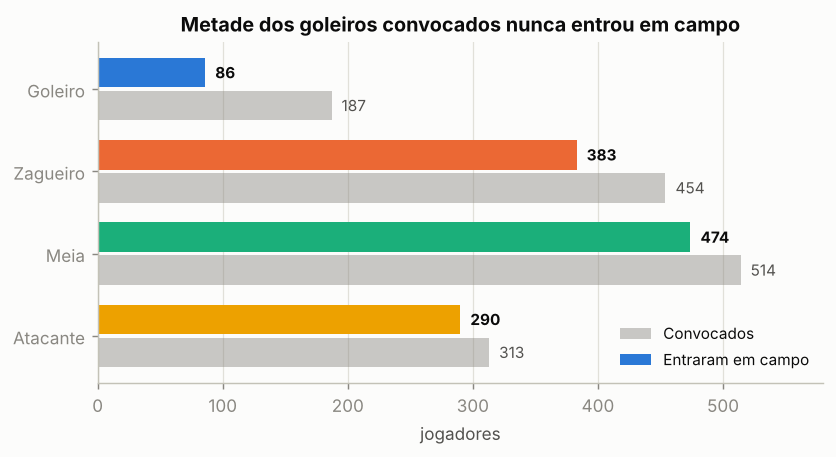

In [13]:
fig, ax = plt.subplots(figsize=(7.2, 3.4))
y = np.arange(len(ORDEM)); h = 0.36
ax.barh(y + h/2 + 0.02, antes.values, h, color=MUDO, alpha=.45, label="Convocados")
ax.barh(y - h/2 - 0.02, depois.values, h,
        color=[CORES[p] for p in ORDEM], label="Entraram em campo")
for i, (a, d) in enumerate(zip(antes.values, depois.values)):
    ax.text(a + 8, i + h/2 + 0.02, f"{a}", va="center", color=SEC, fontsize=8.5)
    ax.text(d + 8, i - h/2 - 0.02, f"{d}", va="center", color=TINTA,
            fontsize=8.5, fontweight="bold")
ax.set_yticks(y, [ROTULO[p] for p in ORDEM]); ax.invert_yaxis()
ax.set_xlabel("jogadores"); ax.set_xlim(0, 580)
ax.set_title("Metade dos goleiros convocados nunca entrou em campo")
ax.legend(loc="lower right", fontsize=8.5)
ax.xaxis.grid(True); ax.set_axisbelow(True)
fig.savefig(FIG / "fig01_classes.png"); plt.show()

O filtro muda o problema de classificação de forma relevante. `GOALKEEPER` cai de 12,7% para
7,0% das amostras (86 jogadores) e vira classe minoritária. O baseline majoritário sobe para
38,4%, que é o número que a rede precisa superar.

## 5. Análise univariada

### 5.1 Zero-inflação

A maioria das métricas é uma contagem rara. Antes de modelar é preciso saber quanto de cada
coluna é simplesmente zero, já que uma coluna 98% zerada contribui quase nada e atrapalha a
padronização.

In [14]:
METRICAS = [c for c in ps.columns if c in DE_BLOCO]
zer = pd.DataFrame({
    "bloco": [DE_BLOCO[c] for c in METRICAS],
    "pct_zero": [(df[c] == 0).mean() * 100 for c in METRICAS],
    "nao_zero": [(df[c] != 0).sum() for c in METRICAS],
    "max": [df[c].max() for c in METRICAS],
    "assimetria": [df[c].skew() for c in METRICAS],
}, index=METRICAS).sort_values("pct_zero", ascending=False)
zer.round(2)

,bloco,pct_zero,nao_zero,max,assimetria
punches,Goleiro,100.00,0,0.00,0.00
goals_scored_other,Gols,99.59,5,1.00,15.63
saves_on_penalty,Goleiro,99.59,5,1.00,15.63
penalty_scored,Gols,98.86,14,2.00,10.87
red_cards,Disciplina,98.38,20,1.00,7.67
goals_scored_head,Gols,96.92,38,2.00,6.20
goals_scored_outside_penalty_area,Gols,96.84,39,3.00,7.01
goals_scored_with_left,Gols,94.57,67,4.00,6.10
goals_conceded,Goleiro,93.84,76,16.00,7.78
saves,Goleiro,93.35,82,21.00,5.37


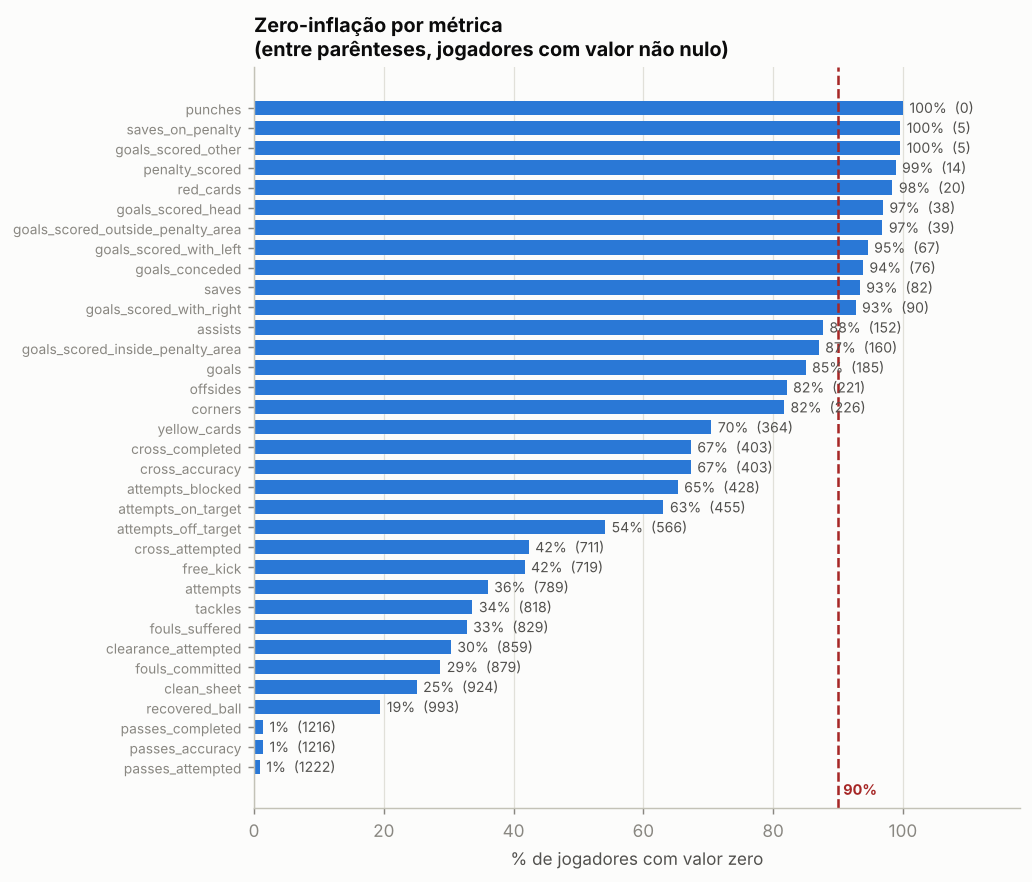

In [15]:
d = zer[zer.pct_zero > 0].sort_values("pct_zero")
fig, ax = plt.subplots(figsize=(7.6, 7.4))
ax.barh(np.arange(len(d)), d.pct_zero, 0.72, color="#2a78d6")
for i, (v, n) in enumerate(zip(d.pct_zero, d.nao_zero)):
    ax.text(v + 1, i, f"{v:.0f}%  ({n})", va="center", color=SEC, fontsize=7.8)
ax.axvline(90, color="#a62726", lw=1.4, ls="--")
ax.text(90.8, -1.4, "90%", color="#a62726", fontsize=8, fontweight="bold")
ax.set_yticks(np.arange(len(d)), d.index, fontsize=7.6)
ax.set_xlim(0, 118); ax.set_xlabel("% de jogadores com valor zero")
ax.set_title("Zero-inflação por métrica\n(entre parênteses, jogadores com valor não nulo)",
             loc="left")
ax.xaxis.grid(True); ax.set_axisbelow(True)
fig.savefig(FIG / "fig03_zeros.png"); plt.show()

In [16]:
SUPORTE_MIN = 0.02
RAROS = [c for c in METRICAS if (df[c] != 0).mean() < SUPORTE_MIN]
pd.DataFrame({
    "nao_zero": [(df[c] != 0).sum() for c in RAROS],
    "suporte_%": [round((df[c] != 0).mean() * 100, 2) for c in RAROS],
    "bloco": [DE_BLOCO[c] for c in RAROS],
}, index=RAROS).rename_axis("coluna com suporte < 2%")

,nao_zero,suporte_%,bloco
coluna com suporte < 2%,,,
goals_scored_other,5,0.41,Gols
penalty_scored,14,1.14,Gols
saves_on_penalty,5,0.41,Goleiro
punches,0,0.00,Goleiro
red_cards,20,1.62,Disciplina


A esparsidade sozinha não desqualifica uma coluna. `saves` é 93,4% zeros e ainda assim será
o melhor discriminador de todo o conjunto (seção 7), porque os zeros são exatamente os
jogadores de linha. O que desqualifica é suporte insuficiente, ou seja, poucas observações
não nulas para a rede extrair alguma regularidade.

Adotamos um critério explícito: menos de 2% de observações não nulas, o que equivale a menos
de 25 dos 1.233 jogadores. Isso elimina cinco colunas.

## 6. O confundidor de exposição

Toda métrica de contagem depende de quanto tempo o jogador ficou em campo, que varia de 1 a
360 minutos. Sem corrigir isso, a rede aprende a distinguir titular de reserva em vez de
zagueiro de meia.

In [17]:
CONTAGENS = [c for c in METRICAS
             if c not in ("minutes_played_official", "matches_appearance",
                          "passes_accuracy", "cross_accuracy", "top_speed")
             and df[c].std() > 0]
m90 = df.minutes_played_official / 90
p90 = df[CONTAGENS].div(m90, axis=0)
p90.columns = [f"{c}_p90" for c in CONTAGENS]

print(f"minutos: min={df.minutes_played_official.min():.0f}  "
      f"mediana={df.minutes_played_official.median():.0f}  "
      f"max={df.minutes_played_official.max():.0f}")
antes_r = df[CONTAGENS].corrwith(df.minutes_played_official)
depois_r = p90.corrwith(df.minutes_played_official)
depois_r.index = CONTAGENS
exp = pd.DataFrame({"bruto": antes_r, "por_90min": depois_r})
exp["reducao"] = exp.bruto.abs() - exp.por_90min.abs()
exp.sort_values("bruto", ascending=False).head(14).round(3)

minutos: min=1  mediana=164  max=360


,bruto,por_90min,reducao
distance_covered,0.83,-0.39,0.43
passes_attempted,0.81,0.01,0.79
passes_completed,0.77,0.04,0.73
recovered_ball,0.62,-0.07,0.55
free_kick,0.57,0.05,0.52
clearance_attempted,0.54,-0.02,0.51
tackles,0.51,-0.09,0.42
fouls_committed,0.48,-0.14,0.34
fouls_suffered,0.45,-0.08,0.36
attempts,0.42,-0.08,0.35


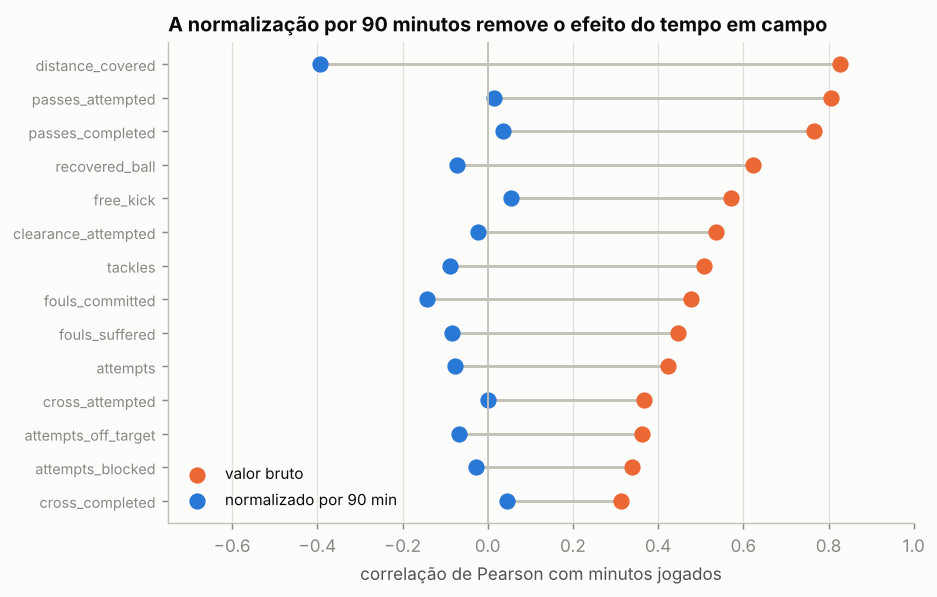

In [18]:
d = exp.sort_values("bruto", ascending=False).head(14).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.4, 4.8))
y = np.arange(len(d))
ax.hlines(y, d.bruto, d.por_90min, color=EIXO, lw=1.6, zorder=1)
ax.scatter(d.bruto, y, s=64, color="#eb6834", zorder=2, label="valor bruto")
ax.scatter(d.por_90min, y, s=64, color="#2a78d6", zorder=2, label="normalizado por 90 min")
ax.axvline(0, color=EIXO, lw=1)
ax.set_yticks(y, d.index, fontsize=8)
ax.set_xlabel("correlação de Pearson com minutos jogados")
ax.set_xlim(-0.75, 1.0)
ax.set_title("A normalização por 90 minutos remove o efeito do tempo em campo", loc="left")
ax.legend(loc="lower left", fontsize=8.5)
ax.xaxis.grid(True); ax.set_axisbelow(True)
fig.savefig(FIG / "fig04_exposicao.png"); plt.show()

Antes da correção, `distance_covered` tem $r = 0{,}83$ com os minutos e `passes_attempted`
$0{,}81$. Essas colunas mediam sobretudo tempo de jogo. Depois da divisão por 90 minutos as
correlações caem para a faixa de $\pm 0{,}1$ e o que resta em cada coluna é uma taxa de
atuação, comparável entre titular e reserva.

A redução não é uniforme. `distance_covered` passa de $+0{,}83$ para $-0{,}39$, ou seja,
inverte o sinal em vez de zerar, e as demais correlações residuais ficam levemente negativas.
A causa é a mesma nos dois casos: quem joga poucos minutos entra na fase final do jogo,
correndo e disputando em ritmo acima da média, o que infla a taxa quando o denominador é
pequeno. O mesmo efeito reaparece como outliers na seção 11.

## 7. Separabilidade por posição

Com as taxas no lugar, a pergunta é se essas colunas realmente distinguem as quatro posições.
Usamos a razão F da ANOVA (variância entre classes sobre variância dentro das classes) e
olhamos as distribuições.

In [19]:
from scipy import stats

base = pd.concat([df[["position", "passes_accuracy", "cross_accuracy",
                      "top_speed", "minutes_played_official"]], p90], axis=1)
cand = [c for c in base.columns if c not in ("position", "minutes_played_official")]

linhas = []
for c in cand:
    grupos = [g[c].dropna().values for _, g in base.groupby("position")]
    if min(len(g) for g in grupos) > 1 and base[c].std() > 0:
        F, pv = stats.f_oneway(*grupos)
        linhas.append({"feature": c, "F": F, "p": pv})
rank = pd.DataFrame(linhas).set_index("feature").sort_values("F", ascending=False)
print("As 15 features que mais separam as posicoes:")
rank.head(15).round(2)

As 15 features que mais separam as posicoes:


,F,p
feature,,
saves_p90,"1,250.61",0.00
goals_conceded_p90,636.12,0.00
top_speed,253.78,0.00
passes_completed_p90,91.36,0.00
passes_attempted_p90,90.76,0.00
clearance_attempted_p90,39.90,0.00
attempts_p90,33.86,0.00
goals_p90,28.27,0.00
goals_scored_inside_penalty_area_p90,25.06,0.00


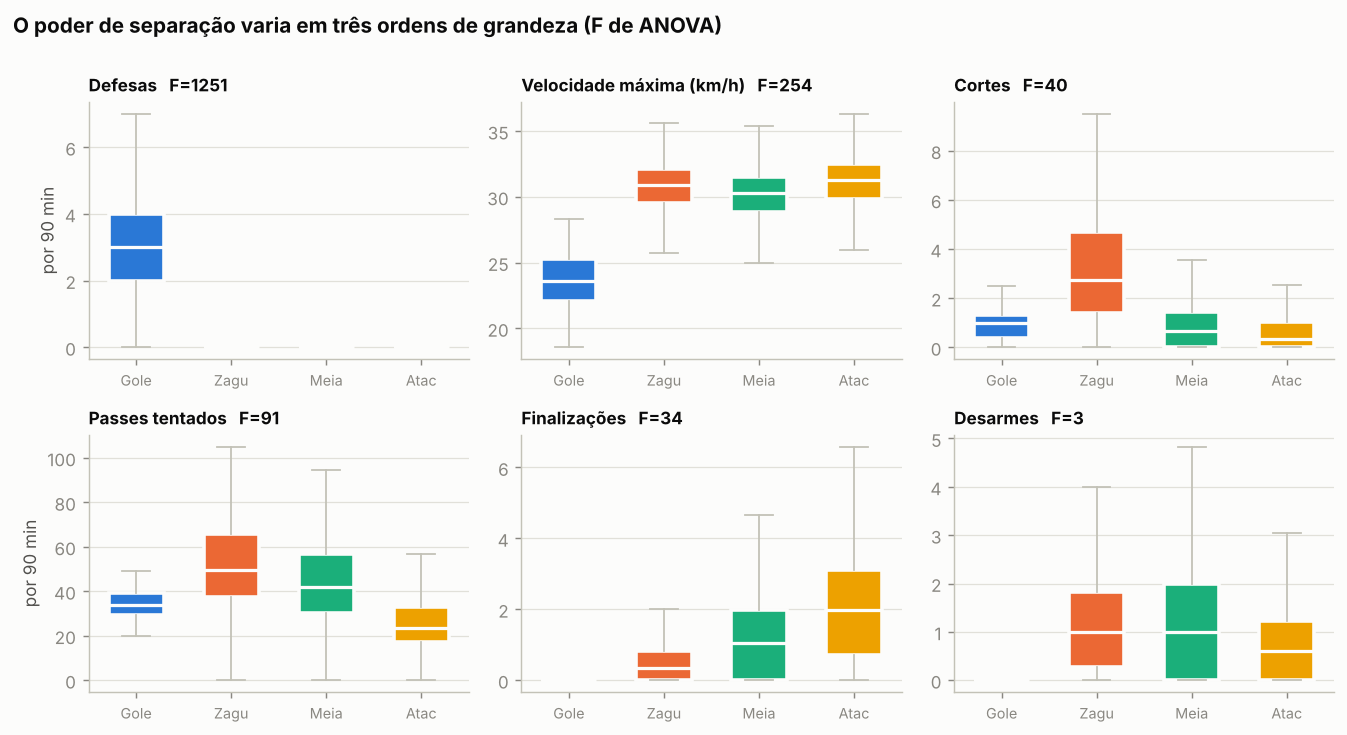

In [20]:
ESCOLHIDAS = ["saves_p90", "top_speed", "clearance_attempted_p90",
              "passes_attempted_p90", "attempts_p90", "tackles_p90"]
TITULO = {"saves_p90": "Defesas", "top_speed": "Velocidade máxima (km/h)",
          "clearance_attempted_p90": "Cortes", "passes_attempted_p90": "Passes tentados",
          "attempts_p90": "Finalizações", "tackles_p90": "Desarmes"}

fig, axes = plt.subplots(2, 3, figsize=(10.4, 5.6))
for ax, c in zip(axes.ravel(), ESCOLHIDAS):
    dados = [base.loc[base.position == p, c].dropna().values for p in ORDEM]
    bp = ax.boxplot(dados, patch_artist=True, widths=.58,
                    showfliers=False, medianprops=dict(color=SUP, lw=1.8),
                    whiskerprops=dict(color=EIXO), capprops=dict(color=EIXO))
    for patch, p in zip(bp["boxes"], ORDEM):
        patch.set(facecolor=CORES[p], edgecolor=SUP, linewidth=2)
    ax.set_xticks(range(1, 5), [ROTULO[p][:4] for p in ORDEM], fontsize=8)
    ax.set_title(f"{TITULO[c]}   F={rank.loc[c,'F']:.0f}", fontsize=9.5, loc="left")
    ax.yaxis.grid(True); ax.set_axisbelow(True)
axes[0, 0].set_ylabel("por 90 min"); axes[1, 0].set_ylabel("por 90 min")
fig.suptitle("O poder de separação varia em três ordens de grandeza (F de ANOVA)", y=1.0,
             fontsize=11.5, fontweight="bold", x=0.009, ha="left")
fig.tight_layout()
fig.savefig(FIG / "fig05_boxplots.png"); plt.show()

O padrão geral é o esperado de um jogo de futebol: defesas e velocidade máxima baixa isolam
o goleiro, cortes marcam o zagueiro, volume de passe marca o meia e finalização marca o
atacante. Entre zagueiro, meia e atacante a sobreposição é clara, e é aí que está a
dificuldade real do problema.

O último painel traz um resultado negativo. Desarmes por 90 minutos quase não separam
posição ($F = 3{,}4$, contra $F = 1251$ das defesas), e zagueiros e meias desarmam em taxa
praticamente idêntica. A intuição de que desarme é coisa de zagueiro não se sustenta nos
dados: o que distingue o zagueiro é o corte (`clearance`).

Sobre o bloco de goleiro, vale um registro explícito. `saves` é não nulo em 82 dos 86
goleiros e em zero jogadores de linha, de modo que a regra `saves > 0` já classifica goleiros
com quase 100% de acerto. Isso precisa constar do relatório do modelo, porque a acurácia
global vai parecer alta por causa de uma classe trivial. A recomendação é reportar a matriz
de confusão e rodar um segundo experimento apenas com jogadores de linha.

In [21]:
g = df[df.position == "GOALKEEPER"]; linha = df[df.position != "GOALKEEPER"]
print(f"goleiros com saves > 0        : {(g.saves > 0).sum():3d} de {len(g)}")
print(f"jogadores de linha com saves>0: {(linha.saves > 0).sum():3d} de {len(linha)}")
print(f"\nregra trivial 'saves > 0' -> acuracia na classe GOALKEEPER: "
      f"{(g.saves > 0).mean()*100:.1f}%")

goleiros com saves > 0        :  82 de 86
jogadores de linha com saves>0:   0 de 1147

regra trivial 'saves > 0' -> acuracia na classe GOALKEEPER: 95.3%


## 8. Correlação e multicolinearidade

Além das identidades exatas da seção 3.5, há pares com correlação acima de 0,9 que duplicam
informação.

In [22]:
corr = base[cand].corr()
alto = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
        .stack().pipe(lambda s: s[s.abs() > 0.9]).sort_values(ascending=False))
print("pares com |r| > 0.9:")
for (a, b), v in alto.items():
    print(f"  {v:+.3f}   {a}  <->  {b}")
print("\npares 'volume x completados' do mesmo bloco:")
for a, b in [("passes_attempted_p90", "passes_completed_p90"),
             ("cross_attempted_p90", "cross_completed_p90"),
             ("attempts_p90", "attempts_on_target_p90")]:
    print(f"  {corr.loc[a, b]:+.3f}   {a}  <->  {b}")

pares com |r| > 0.9:
  +0.977   passes_attempted_p90  <->  passes_completed_p90
  +0.936   goals_p90  <->  goals_scored_inside_penalty_area_p90

pares 'volume x completados' do mesmo bloco:
  +0.977   passes_attempted_p90  <->  passes_completed_p90
  +0.719   cross_attempted_p90  <->  cross_completed_p90
  +0.662   attempts_p90  <->  attempts_on_target_p90


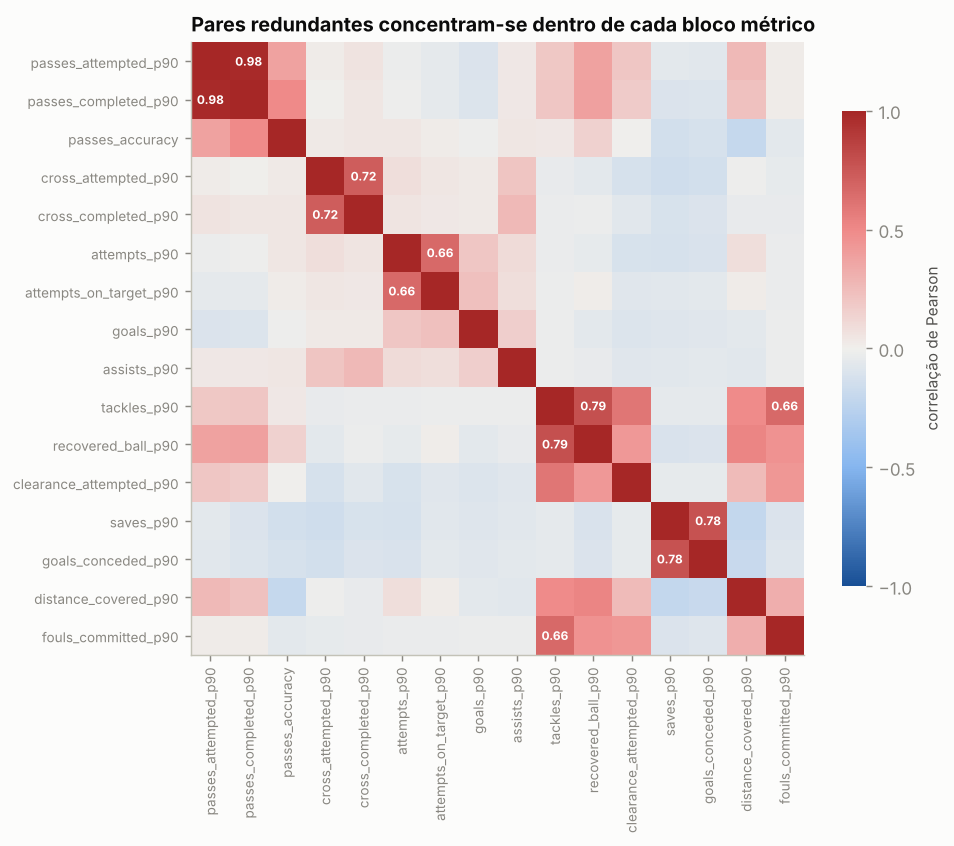

In [23]:
MOSTRA = ["passes_attempted_p90", "passes_completed_p90", "passes_accuracy",
          "cross_attempted_p90", "cross_completed_p90", "attempts_p90",
          "attempts_on_target_p90", "goals_p90", "assists_p90", "tackles_p90",
          "recovered_ball_p90", "clearance_attempted_p90", "saves_p90",
          "goals_conceded_p90", "distance_covered_p90", "fouls_committed_p90"]
c = base[MOSTRA].corr()
fig, ax = plt.subplots(figsize=(7.6, 6.6))
im = ax.imshow(c, cmap=CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(MOSTRA)), MOSTRA, rotation=90, fontsize=7.5)
ax.set_yticks(range(len(MOSTRA)), MOSTRA, fontsize=7.5)
for i in range(len(MOSTRA)):
    for j in range(len(MOSTRA)):
        if abs(c.iloc[i, j]) > 0.65 and i != j:
            ax.text(j, i, f"{c.iloc[i,j]:.2f}", ha="center", va="center",
                    fontsize=6.6, color="#ffffff", fontweight="bold")
cb = fig.colorbar(im, ax=ax, shrink=.72, ticks=[-1, -.5, 0, .5, 1])
cb.outline.set_visible(False); cb.ax.tick_params(colors=MUDO)
cb.set_label("correlação de Pearson", color=SEC, fontsize=8.5)
ax.set_title("Pares redundantes concentram-se dentro de cada bloco métrico", loc="left")
fig.savefig(FIG / "fig06_corr.png"); plt.show()

`passes_attempted` e `passes_completed` chegam a $r = 0{,}98$ mesmo depois da normalização,
então o par carrega uma informação só. Mantemos o volume (`attempted`) e a qualidade
(`accuracy` recalculada) e descartamos `completed`, já que essa dupla reconstrói o par
original sem a colinearidade. A mesma lógica se aplica aos cruzamentos, cujo par é menos
extremo mas segue redundante.

## 9. Conjunto final de variáveis

Aplicando as decisões acumuladas:

In [24]:
IDENTIFICADORES = ["player_id", "player_name", "team_id", "team_name", "country_code"]
REDUNDANTES = ["goals", "goals_scored_inside_penalty_area",
               "goals_scored_outside_penalty_area", "attempts",
               "passes_completed", "cross_completed"]
EXPOSICAO = ["minutes_played_official", "matches_appearance"]

MOTIVO = {
    **{c: "identificador, permitiria memorizar o indivíduo" for c in IDENTIFICADORES[:3]},
    "team_name":   "54 níveis categóricos (~23 jogadores cada); seleção não define função tática",
    "country_code": "duplica team_name",
    "punches":     "variância nula: zero para os 1.233 jogadores que entraram em campo",
    "goals_scored_other":  "suporte < 2% (apenas 5 jogadores)",
    "saves_on_penalty":    "suporte < 2% (apenas 5 jogadores)",
    "penalty_scored":      "suporte < 2% (apenas 14 jogadores)",
    "red_cards":           "suporte < 2% (apenas 20 jogadores)",
    "goals":       "soma exata das 4 colunas por parte do corpo",
    "goals_scored_inside_penalty_area":  "segunda decomposição do mesmo total",
    "goals_scored_outside_penalty_area": "segunda decomposição do mesmo total",
    "attempts":    "soma exata de on_target + off_target + blocked",
    "passes_completed": "r = 0,98 com passes_attempted; a qualidade já está em passes_accuracy",
    "cross_completed":  "idem, com cross_attempted / cross_accuracy",
    "minutes_played_official": "vira denominador da normalização, não entrada",
    "matches_appearance":      "exposição, não função tática",
}
GRUPO = {**{c: "1. identificador" for c in IDENTIFICADORES},
         **{c: "2. suporte insuficiente" for c in RAROS},
         **{c: "3. redundância estrutural" for c in REDUNDANTES},
         **{c: "4. exposição" for c in EXPOSICAO}}
DESCARTADAS = IDENTIFICADORES + RAROS + REDUNDANTES + EXPOSICAO

print(f"{len(DESCARTADAS)} colunas descartadas + 1 alvo ('position') "
      f"= {len(DESCARTADAS) + 1} de {ps.shape[1]}")
pd.DataFrame({"grupo": pd.Series(GRUPO), "motivo": pd.Series(MOTIVO)}
             ).loc[DESCARTADAS].sort_values("grupo").rename_axis("coluna descartada")

18 colunas descartadas + 1 alvo ('position') = 19 de 44


,grupo,motivo
coluna descartada,,
player_id,1. identificador,"identificador, permitiria memorizar o indivíduo"
player_name,1. identificador,"identificador, permitiria memorizar o indivíduo"
team_id,1. identificador,"identificador, permitiria memorizar o indivíduo"
team_name,1. identificador,54 níveis categóricos (~23 jogadores cada); se...
country_code,1. identificador,duplica team_name
red_cards,2. suporte insuficiente,suporte < 2% (apenas 20 jogadores)
saves_on_penalty,2. suporte insuficiente,suporte < 2% (apenas 5 jogadores)
punches,2. suporte insuficiente,variância nula: zero para os 1.233 jogadores q...
goals_scored_other,2. suporte insuficiente,suporte < 2% (apenas 5 jogadores)


In [25]:
FEATURES = ([f"{c}_p90" for c in CONTAGENS if c not in set(DESCARTADAS)]
            + ["passes_accuracy", "cross_accuracy", "top_speed"])
X = base[FEATURES].copy()
y = df.position.copy()
print(f"X: {X.shape[0]} amostras x {X.shape[1]} features")
print(f"y: {y.nunique()} classes -> {y.value_counts().to_dict()}")
print(f"\nnulos restantes: {X.isna().sum()[X.isna().sum() > 0].to_dict()}")

X: 1233 amostras x 25 features
y: 4 classes -> {'MIDFIELDER': 474, 'DEFENDER': 383, 'FORWARD': 290, 'GOALKEEPER': 86}

nulos restantes: {'distance_covered_p90': 70, 'top_speed': 70}


### 9.1 O último bloco de ausências

Sobram 70 nulos em `top_speed` e `distance_covered`, dados de rastreamento que a UEFA não
publicou para algumas partidas. São 5,7% das linhas, espalhados por todas as posições.

Um cuidado metodológico: imputar pela mediana da posição usaria o rótulo $y$ para construir
$x$, o que é vazamento. A imputação precisa ser pela mediana global e, no trabalho seguinte,
ajustada apenas no conjunto de treino.

In [26]:
falt = X.isna().any(axis=1)
print(f"linhas com rastreamento ausente: {falt.sum()} ({falt.mean()*100:.1f}%)")
print(df.loc[falt, "position"].value_counts().to_dict())
X = X.fillna(X.median(numeric_only=True))   # provisório; refazer dentro do split

linhas com rastreamento ausente: 70 (5.7%)
{'MIDFIELDER': 24, 'DEFENDER': 21, 'FORWARD': 16, 'GOALKEEPER': 9}


## 10. Visualização em duas dimensões (PCA)

A PCA mostra se as quatro classes ocupam regiões distintas do espaço de entrada. Também
serve como prévia do que uma camada densa faz, que é projetar em menos dimensões.

Antes de projetar, um cuidado com a cauda do espaço de entrada.

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Z = StandardScaler().fit_transform(X)
pca = PCA(n_components=10).fit(Z)
P = pca.transform(Z)
ev = pca.explained_variance_ratio_
print(f"sem tratamento de extremos:  PC1={ev[0]*100:.1f}%  PC2={ev[1]*100:.1f}%  "
      f"PC1+PC2={ev[:2].sum()*100:.1f}%")

# quem domina a PC1?
dom = pd.DataFrame({"PC1": P[:, 0], "minutos": df.minutes_played_official.values},
                   index=X.index).nlargest(5, "PC1")
print(f"\nos 5 maiores valores de PC1 tem minutos jogados = "
      f"{dom.minutos.astype(int).tolist()}")
print(f"correlacao |PC1| x minutos jogados: "
      f"{np.corrcoef(np.abs(P[:, 0]), df.minutes_played_official)[0,1]:+.3f}")

sem tratamento de extremos:  PC1=14.4%  PC2=10.4%  PC1+PC2=24.7%

os 5 maiores valores de PC1 tem minutos jogados = [1, 1, 2, 2, 2]
correlacao |PC1| x minutos jogados: -0.165


Os cinco maiores valores da PC1 pertencem a jogadores com 1 ou 2 minutos em campo. Uma
entrada de 1 minuto com um desarme vira 90 desarmes por 90 minutos, taxa aritmeticamente
correta e sem sentido prático. Esses pontos esticam os eixos e comprimem visualmente o resto
da amostra.

A correção é winsorizar, ou seja, recortar cada variável nos percentis 1 e 99, limitando o
extremo sem descartar a linha. É o mesmo tratamento aplicado na seção 12, antes do split.

In [28]:
lo, hi = X.quantile(0.01), X.quantile(0.99)
Xw = X.clip(lo, hi, axis=1)

Zw = StandardScaler().fit_transform(Xw)
pcaw = PCA(n_components=10).fit(Zw)
P = pcaw.transform(Zw)
ev = pcaw.explained_variance_ratio_
print(f"com winsorização p1-p99:     PC1={ev[0]*100:.1f}%  PC2={ev[1]*100:.1f}%  "
      f"PC1+PC2={ev[:2].sum()*100:.1f}%   10 PCs={ev.sum()*100:.1f}%")

for k in (0, 1):
    carga = pd.Series(pcaw.components_[k], index=FEATURES).sort_values()
    print(f"\nPC{k+1}, cargas extremas:")
    print(pd.concat([carga.head(4), carga.tail(4)]).round(3).to_string())

com winsorização p1-p99:     PC1=13.0%  PC2=10.7%  PC1+PC2=23.7%   10 PCs=65.9%

PC1, cargas extremas:
top_speed                 -0.36
attempts_on_target_p90    -0.28
cross_attempted_p90       -0.28
attempts_blocked_p90      -0.25
clearance_attempted_p90    0.13
free_kick_p90              0.15
goals_conceded_p90         0.37
saves_p90                  0.39

PC2, cargas extremas:
saves_p90                 -0.31
goals_conceded_p90        -0.30
attempts_on_target_p90    -0.21
attempts_blocked_p90      -0.16
tackles_p90                0.27
clearance_attempted_p90    0.29
passes_attempted_p90       0.31
recovered_ball_p90         0.45


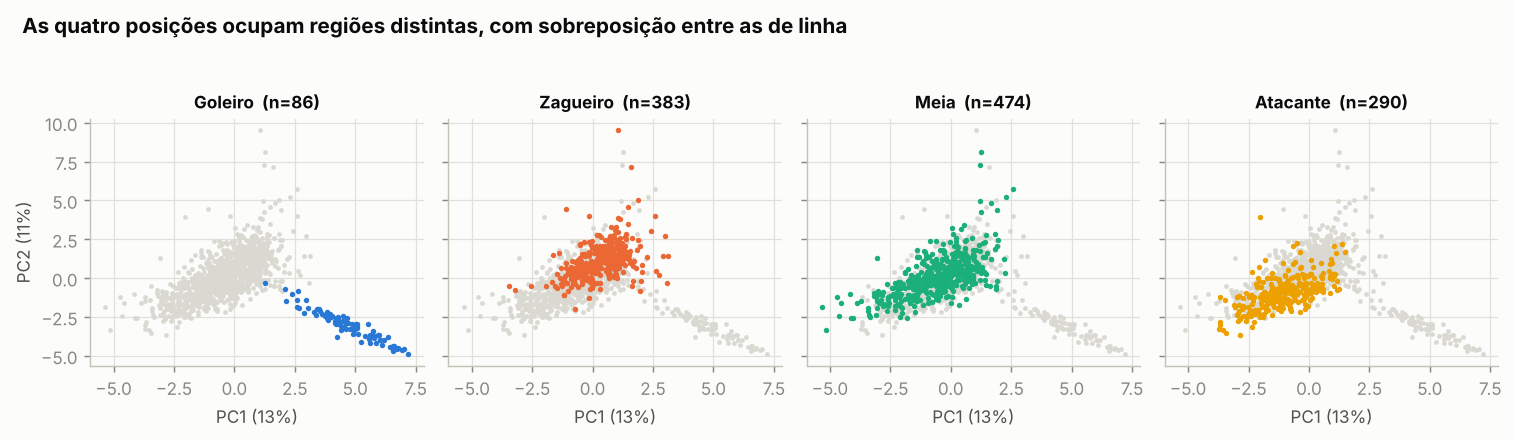

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(11.6, 3.2), sharex=True, sharey=True)
for ax, p in zip(axes, ORDEM):
    m = (y == p).values
    ax.scatter(P[~m, 0], P[~m, 1], s=7, color="#d9d8d1", lw=0, zorder=1)
    ax.scatter(P[m, 0], P[m, 1], s=9, color=CORES[p], lw=0, zorder=2)
    ax.set_title(f"{ROTULO[p]}  (n={m.sum()})", fontsize=9.5)
    ax.set_xlabel(f"PC1 ({ev[0]*100:.0f}%)")
    ax.grid(True); ax.set_axisbelow(True)
axes[0].set_ylabel(f"PC2 ({ev[1]*100:.0f}%)")
fig.suptitle("As quatro posições ocupam regiões distintas, com sobreposição entre as de linha",
             y=1.04, fontsize=11.5, fontweight="bold", x=0.009, ha="left")
fig.tight_layout()
fig.savefig(FIG / "fig07_pca.png"); plt.show()

Os goleiros formam um braço inteiramente apartado, estendendo-se para PC1 alto e PC2 baixo,
o que confirma visualmente o atalho da seção 7. As cargas explicam o eixo: a PC1 é dominada
por defesas ($+0{,}39$), gols sofridos ($+0{,}37$) e velocidade máxima baixa ($-0{,}36$).
Não é um eixo tático de campo, é o eixo goleiro contra jogador de linha.

Entre os jogadores de linha a estrutura aparece na PC2, carregada por bola recuperada
($+0{,}45$), passes tentados ($+0{,}31$) e cortes ($+0{,}29$). Zagueiros ocupam a faixa
superior, atacantes a inferior-esquerda, e os meias se espalham pela região intermediária,
sobrepondo-se aos dois. É um gradiente com fronteiras difusas e não alinhadas aos eixos.

Dois números reforçam a escolha do modelo. PC1 e PC2 juntas explicam apenas 23,7% da
variância, e são necessárias 10 componentes para chegar a 66%. A informação que distingue as
posições está distribuída por muitas dimensões e não é linearmente separável, que é
exatamente o caso em que uma camada oculta com ativação não linear supera um classificador
linear.

## 11. Outliers

Valores extremos aqui tendem a ser jogadores reais de elite ou de amostra curta, não erro de
medição. Removê-los descartaria sinal.

In [30]:
z = pd.DataFrame(Z, columns=FEATURES, index=X.index)
extremos = (z.abs() > 5).sum(axis=1).sort_values(ascending=False)
print(f"linhas com ao menos uma feature |z| > 5: {(extremos > 0).sum()} "
      f"({(extremos > 0).mean()*100:.1f}%)\n")
top = extremos.head(6).index
df.loc[top, ["player_name", "position", "minutes_played_official"]].assign(
    features_extremas=extremos.head(6),
    motivo=lambda d: np.where(d.minutes_played_official < 30,
                              "amostra curta (taxa inflada)", "desempenho real extremo"))

linhas com ao menos uma feature |z| > 5: 115 (9.3%)



,player_name,position,minutes_played_official,features_extremas,motivo
1228,Oleksandr Drambayev,DEFENDER,1.00,6,amostra curta (taxa inflada)
1225,Stjepan Radeljić,DEFENDER,1.00,5,amostra curta (taxa inflada)
1230,Kristian Thorstvedt,FORWARD,1.00,4,amostra curta (taxa inflada)
1221,Vasilije Kostov,MIDFIELDER,2.00,3,amostra curta (taxa inflada)
1217,Aleksejs Saveļjevs,MIDFIELDER,2.00,3,amostra curta (taxa inflada)
1216,Vitaly Janelt,MIDFIELDER,2.00,3,amostra curta (taxa inflada)


A causa dominante é amostra curta: um jogador que entrou por 5 minutos e deu um carrinho
registra 18 desarmes por 90 minutos. Em vez de remover linhas, aplicamos winsorização em
p1-p99 na seção 12 e recomendamos testar um piso mínimo de minutos como experimento de
sensibilidade no trabalho seguinte.

## 12. Preparação final: padronização e divisão treino / validação / teste

A disciplina pede explicitamente os três conjuntos. A divisão é estratificada porque
`GOALKEEPER` tem apenas 86 amostras e uma divisão aleatória simples poderia deixar o
conjunto de teste com pouquíssimos goleiros.

Winsorização e padronização são ajustadas somente no conjunto de treino e depois aplicadas
aos outros dois. Calcular percentis ou médias sobre o conjunto completo faria o teste
influenciar o pré-processamento, que é uma forma sutil de vazamento.

In [31]:
from sklearn.model_selection import train_test_split

X_tr, X_tmp, y_tr, y_tmp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
X_va, X_te, y_va, y_te = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)

# Winsorizacao e padronizacao ajustadas so no treino; validacao e teste apenas recebem
lo_tr, hi_tr = X_tr.quantile(0.01), X_tr.quantile(0.99)
corta = lambda a: a.clip(lo_tr, hi_tr, axis=1)
esc = StandardScaler().fit(corta(X_tr))
X_tr_s, X_va_s, X_te_s = (esc.transform(corta(a)) for a in (X_tr, X_va, X_te))

print(f"treino    {len(X_tr):5d}  ({len(X_tr)/len(X)*100:.0f}%)")
print(f"validacao {len(X_va):5d}  ({len(X_va)/len(X)*100:.0f}%)")
print(f"teste     {len(X_te):5d}  ({len(X_te)/len(X)*100:.0f}%)\n")
pd.DataFrame({"treino": y_tr.value_counts(normalize=True),
              "validacao": y_va.value_counts(normalize=True),
              "teste": y_te.value_counts(normalize=True)}).reindex(ORDEM).mul(100).round(1)

treino      863  (70%)
validacao   185  (15%)
teste       185  (15%)



,treino,validacao,teste
position,,,
GOALKEEPER,7.00,7.00,7.00
DEFENDER,31.10,30.80,31.40
MIDFIELDER,38.50,38.40,38.40
FORWARD,23.50,23.80,23.20


In [32]:
classes = np.array(ORDEM)
cod = {c: i for i, c in enumerate(classes)}
onehot = lambda s: np.eye(len(classes))[s.map(cod).values]

np.savez_compressed(
    "dados_preparados.npz",
    X_train=X_tr_s, X_val=X_va_s, X_test=X_te_s,
    y_train=onehot(y_tr), y_val=onehot(y_va), y_test=onehot(y_te),
    y_train_lab=y_tr.values, y_val_lab=y_va.values, y_test_lab=y_te.values,
    features=np.array(FEATURES), classes=classes)
pd.Series(FEATURES, name="feature").to_csv("features_finais.csv", index=False)

print(f"salvo: dados_preparados.npz  ({X_tr_s.shape[1]} features, "
      f"{len(classes)} classes em one-hot)")
print(f"media/desvio no treino apos padronizar: "
      f"{X_tr_s.mean():.2e} / {X_tr_s.std():.3f}")

salvo: dados_preparados.npz  (25 features, 4 classes em one-hot)
media/desvio no treino apos padronizar: 6.62e-17 / 1.000


## 13. Resumo da análise

**O conjunto.** *UEFA Nations League 2026/27* (Kaggle, CC BY-SA 4.0), extraído das APIs
oficiais da UEFA: 7 arquivos CSV, 266 colunas, 104 partidas, 54 seleções e 1.468 jogadores.
A tabela de trabalho é `players_summary.csv` (1.468 × 44), a única com amostras suficientes
para treinar uma rede neural.

**Tarefa definida.** Classificação multiclasse da posição tática do jogador em 4 classes, a
partir de 25 métricas de desempenho normalizadas por 90 minutos, com MLP densa, saída
`softmax` e treinamento por backpropagation. Baseline a superar: 38,4%, a frequência da
classe majoritária `MIDFIELDER`.

**O que a análise encontrou:**

1. 235 jogadores (16%) nunca entraram em campo e não possuem métrica alguma. Entre os
   goleiros a proporção chega a 54%, reflexo da regra de convocar três e usar um. Removidos,
   n cai de 1.468 para 1.233 e `GOALKEEPER` passa de 12,7% para 7,0% das amostras.
2. O tempo em campo dominava todas as contagens ($r = 0{,}83$ para distância percorrida,
   $0{,}81$ para passes tentados). Sem correção, a rede aprenderia a separar titular de
   reserva em vez de zagueiro de meia. A normalização por 90 minutos é a transformação mais
   importante de toda a preparação.
3. Três colunas foram preenchidas com zero em vez de ausência (`cross_accuracy`,
   `yellow_cards`, `red_cards`), o que criaria sinal falso se as 235 linhas fossem mantidas.
4. `passes_accuracy` não é reprodutível a partir das colunas que a definem. Apenas 59% das
   linhas ficam dentro de ±1 p.p. do valor recalculado e há um grupo com aproveitamento
   perfeito gravado como 50%. A coluna foi recalculada.
5. Redundâncias estruturais: `goals` é a soma exata das quatro colunas por parte do corpo,
   `attempts` a soma de três, e `passes_attempted` e `passes_completed` mantêm $r = 0{,}98$
   mesmo após a normalização.
6. Cinco linhas com erro na fonte, reveladas pelos testes de identidade: gols sem parte do
   corpo ou região atribuída e finalizações cujas parcelas não somam o total.
7. Um jogador duplicado, com dois `player_id` e posições conflitantes, mostrando que
   `player_id` não é chave confiável de pessoa.
8. A esparsidade não é defeito, a falta de suporte é. `saves` tem 93% de zeros e é o melhor
   discriminador do conjunto, enquanto `goals_scored_other` e `saves_on_penalty` têm apenas
   5 observações não nulas cada e não sustentam aprendizado.
9. A classe `GOALKEEPER` é trivialmente separável. `saves > 0` acerta 95,3% dos goleiros e
   nunca dispara em jogador de linha (0 de 1.147). A acurácia global do modelo será inflada
   por isso, daí a recomendação de reportar matriz de confusão e rodar um experimento
   paralelo só com jogadores de linha.
10. Desarmes quase não separam posição ($F = 3{,}4$). Zagueiros e meias desarmam em taxa
    equivalente, e o que marca o zagueiro é o corte.
11. As taxas de jogadores com poucos minutos ocupam toda a cauda da primeira componente, já
    que os cinco extremos têm 1 ou 2 minutos em campo. A winsorização em p1-p99 é necessária
    para que a projeção fique legível e também antes do treinamento.
12. A informação está distribuída por muitas dimensões. As duas primeiras componentes
    explicam só 23,7% da variância e são necessárias 10 para chegar a 66%. Somado às
    fronteiras sobrepostas entre as classes de linha, é o argumento técnico a favor de uma
    MLP com camada oculta em vez de um classificador linear.

**Colunas descartadas:** 18 das 44, mais o alvo. São 5 identificadores, 5 com suporte
inferior a 2%, 6 redundâncias estruturais e 2 de exposição, que viraram denominador.
Restaram 25 variáveis de entrada e 1.233 amostras.

**Pendências para o trabalho 2:** imputar `top_speed` e `distance_covered` (5,7% de ausência)
usando apenas estatísticas do conjunto de treino; tratar o desbalanceamento de `GOALKEEPER`
(86 amostras) com pesos de classe na função de custo; testar um piso mínimo de minutos como
experimento de sensibilidade.